# Results viewer: *General or Specific?*

This notebook loads the local JSON run artifacts for the CREMA-D reproduction, summarizes SER validation and gender-attack metrics, and plots the runs that are actually available. Run it from any directory; paths are resolved relative to this notebook.

## Current evidence at a glance

The current fold-1 pilot has an unprotected SER validation result of **ACC 0.7063 / UAR 0.7009** and UDP at epsilon 10 of **ACC 0.6867 / UAR 0.6815**. A fast, downsampled CPU gender-attack pilot using five updates reports **SR 0.6492 / UASR 0.6352**. The attack result is a runtime-deviation diagnostic; it is not directly comparable with the paper's fold-1 baseline attack result (**0.837 / 0.829**). Voice-Ind/Gender-Ind and the full attack evaluation remain incomplete.

These are pilot results, not a completed replication. The paper reports 3-fold baseline metrics and defence curves; the notebook will show missing runs as missing rather than treating them as zero.

## Methods and provenance

The target study uses CREMA-D, actor-level clients, FedAvg, a two-hidden-layer SER network, a shadow-client gender attack on first-layer updates, and UDP, Voice-Ind, and Gender-Ind. The project details and deviations are in [`paper_analysis_for_phd.md`](../paper_analysis_for_phd.md) and [`reproduction_decisions.md`](../reproduction_decisions.md). Run outputs are local under `outputs/runs/` and are intentionally excluded from version control. The notebook reads any matching artifacts found there.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def locate_project(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "outputs" / "runs").is_dir() and (candidate / "scripts").is_dir():
            return candidate
    raise FileNotFoundError("Could not find project outputs/runs and scripts. Open this notebook inside the reproduction project.")

PROJECT_ROOT = locate_project(Path.cwd())
RUNS_ROOT = PROJECT_ROOT / "outputs" / "runs"
PAPER_BASELINE = pd.DataFrame([
    {"fold": 1, "attack_sr": 0.837, "attack_uasr": 0.829, "ser_acc": 0.663, "ser_uar": 0.595},
    {"fold": 2, "attack_sr": 0.847, "attack_uasr": 0.838, "ser_acc": 0.666, "ser_uar": 0.601},
    {"fold": 3, "attack_sr": 0.817, "attack_uasr": 0.791, "ser_acc": 0.656, "ser_uar": 0.619},
])
plt.style.use("seaborn-v0_8-whitegrid")
print(f"Project: {PROJECT_ROOT}")
print(f"Run-artifact directory: {RUNS_ROOT}")
print(f"Paper baseline folds: {len(PAPER_BASELINE)}")

Project: C:\Users\charl\OneDrive\Documents\PhD\general-or-specific-reproduction
Run-artifact directory: C:\Users\charl\OneDrive\Documents\PhD\general-or-specific-reproduction\outputs\runs
Paper baseline folds: 3


## 1. Inventory available experiment artifacts

The inventory is generated from saved JSON files. A listed file indicates an artifact exists; it does not imply that the run matches the paper exactly.

In [2]:
def read_json(path: Path):
    with path.open(encoding="utf-8") as stream:
        return json.load(stream)

validation_files = sorted(RUNS_ROOT.glob("fold*/**/ser_validation.json"))
run_files = sorted(RUNS_ROOT.glob("fold*/**/run.json"))
attack_files = sorted(RUNS_ROOT.glob("fold*/attack*.json"))

validation_rows = []
for path in validation_files:
    run = read_json(path)
    meta_path = path.with_name("run.json")
    meta = read_json(meta_path) if meta_path.exists() else {}
    final = run.get("final", {})
    validation_rows.append({
        "fold": meta.get("fold", path.parts[-4] if len(path.parts) >= 4 else "?"),
        "role": meta.get("role", "unknown"),
        "defense": meta.get("defense", "unknown"),
        "epsilon": meta.get("epsilon"),
        "round": final.get("round"),
        "SER ACC": final.get("accuracy"),
        "SER UAR": final.get("uar"),
        "artifact": path.relative_to(PROJECT_ROOT).as_posix(),
    })

validation_df = pd.DataFrame(validation_rows)
if not validation_df.empty:
    display(validation_df.sort_values(["fold", "role", "defense", "epsilon"], na_position="first").reset_index(drop=True).round(4))
else:
    print("No ser_validation.json files found yet.")

attack_rows = []
for path in attack_files:
    result = read_json(path)
    attack_rows.append({
        "run": path.stem,
        "updates per client": result.get("num_samples_per_client"),
        "downsampled attack": result.get("attack_model_downsampled"),
        "shadow actors": result.get("shadow_actors"),
        "private actors": result.get("private_actors"),
        "attack SR": result.get("success_rate"),
        "attack UASR": result.get("unweighted_average_success_recall"),
        "artifact": path.relative_to(PROJECT_ROOT).as_posix(),
    })
attack_df = pd.DataFrame(attack_rows)
if not attack_df.empty:
    display(attack_df.round(4))
else:
    print("No attack result JSON files found yet.")

,fold,role,defense,epsilon,round,SER ACC,SER UAR,artifact
0,1,private,none,NaN,200,0.7063,0.7009,outputs/runs/fold1/private/none/ser_validation...
1,1,private,udp,10.0,200,0.6867,0.6815,outputs/runs/fold1/private/udp/epsilon_10/ser_...
2,1,shadow,none,NaN,200,0.7015,0.5688,outputs/runs/fold1/shadow/none/ser_validation....
3,1,shadow,udp,10.0,200,0.6955,0.5848,outputs/runs/fold1/shadow/udp/epsilon_10/ser_v...


,run,updates per client,downsampled attack,shadow actors,private actors,attack SR,attack UASR,artifact
0,attack_none_n5_fast,5,None,30,61,0.6492,0.6352,outputs/runs/fold1/attack_none_n5_fast.json
1,attack_none_n5_fast_pilot,5,None,30,61,0.6057,0.5809,outputs/runs/fold1/attack_none_n5_fast_pilot.json


## 2. SER utility over federated rounds

The chart shows private-client validation metrics available in the run artifacts. It is a fold-1 pilot comparison; it does not average across the paper's three folds. The paper's fold-1 and three-fold baseline values are shown separately for context.

C:\Users\charl\AppData\Local\Temp\ipykernel_48908\3202338294.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  round_df = pd.concat(round_frames, ignore_index=True) if round_frames else pd.DataFrame()


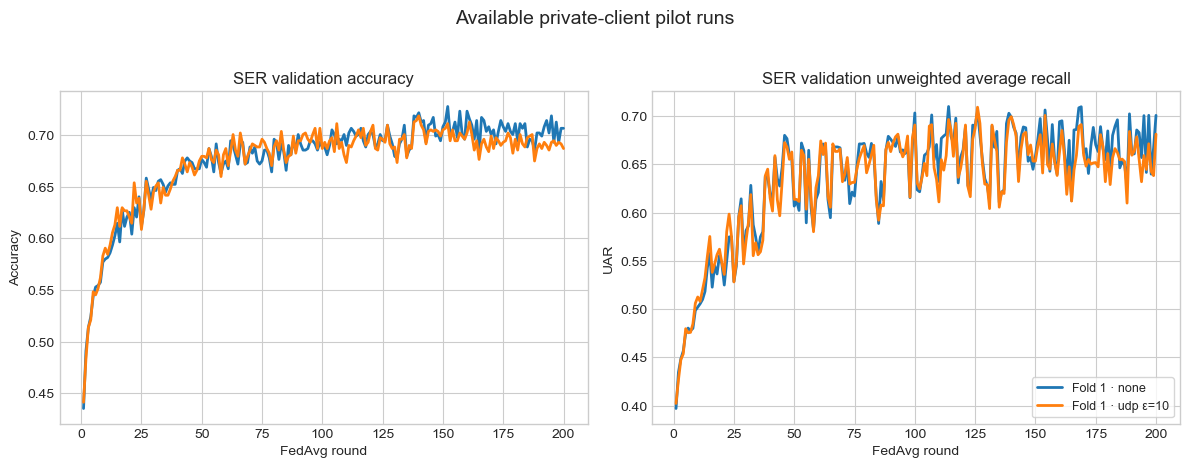

In [3]:
def load_rounds(path: Path):
    payload = read_json(path)
    frame = pd.DataFrame(payload.get("rounds", []))
    if frame.empty:
        return frame
    frame["artifact"] = path.relative_to(PROJECT_ROOT).as_posix()
    meta_path = path.with_name("run.json")
    meta = read_json(meta_path) if meta_path.exists() else {}
    frame["defense"] = meta.get("defense", "unknown")
    frame["epsilon"] = meta.get("epsilon")
    frame["role"] = meta.get("role", "unknown")
    frame["fold"] = meta.get("fold", "?")
    return frame

round_frames = [load_rounds(path) for path in validation_files]
round_frames = [frame for frame in round_frames if not frame.empty and (frame["role"] == "private").all()]
round_df = pd.concat(round_frames, ignore_index=True) if round_frames else pd.DataFrame()

if round_df.empty:
    print("No per-round private-client validation series are available.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
    for (fold, defense, epsilon), group in round_df.groupby(["fold", "defense", "epsilon"], dropna=False):
        label = f"Fold {fold} · {defense}" + (f" ε={epsilon:g}" if pd.notna(epsilon) else "")
        group = group.sort_values("round")
        axes[0].plot(group["round"], group["accuracy"], label=label, linewidth=2)
        axes[1].plot(group["round"], group["uar"], label=label, linewidth=2)
    axes[0].set(title="SER validation accuracy", xlabel="FedAvg round", ylabel="Accuracy")
    axes[1].set(title="SER validation unweighted average recall", xlabel="FedAvg round", ylabel="UAR")
    axes[1].legend(frameon=True, fontsize=9)
    fig.suptitle("Available private-client pilot runs", y=1.03, fontsize=14)
    fig.tight_layout()
    plt.show()

## 3. Published baseline versus current pilot

The published values below are reported in the target paper's baseline table. The local pilot uses an inferred feature pipeline and a different actor split; the comparison is diagnostic, not a controlled replication estimate.

,source,SER ACC,SER UAR
0,Paper baseline · fold 1,0.6630,0.5950
1,Paper baseline · mean of 3 folds,0.6617,0.6050
2,Local pilot · no protection,0.7063,0.7009
3,Local pilot · UDP ε=10,0.6867,0.6815


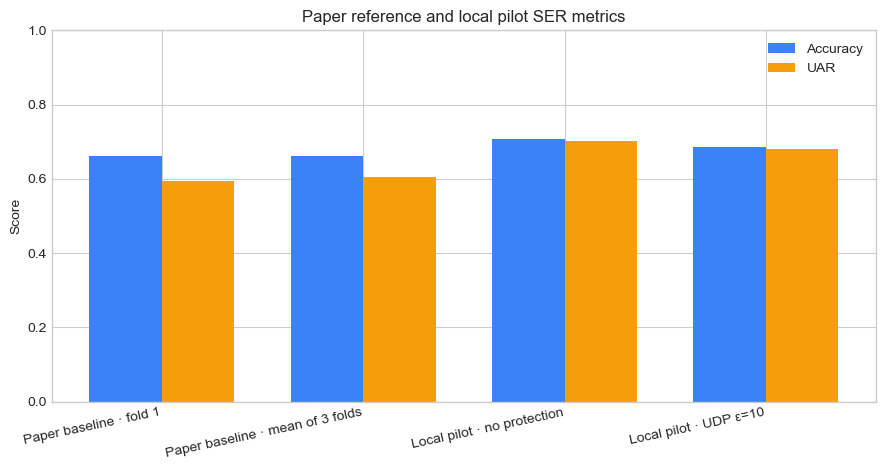

In [4]:
paper_mean = PAPER_BASELINE[["ser_acc", "ser_uar"]].mean()
paper_fold1 = PAPER_BASELINE.loc[PAPER_BASELINE["fold"] == 1].iloc[0]
local_baseline = validation_df[(validation_df["role"] == "private") & (validation_df["defense"] == "none")]
local_udp10 = validation_df[(validation_df["role"] == "private") & (validation_df["defense"] == "udp") & (validation_df["epsilon"] == 10)]

comparison_rows = [
    {"source": "Paper baseline · fold 1", "SER ACC": paper_fold1["ser_acc"], "SER UAR": paper_fold1["ser_uar"]},
    {"source": "Paper baseline · mean of 3 folds", "SER ACC": paper_mean["ser_acc"], "SER UAR": paper_mean["ser_uar"]},
]
for label, subset in [("Local pilot · no protection", local_baseline), ("Local pilot · UDP ε=10", local_udp10)]:
    if not subset.empty:
        row = subset.iloc[0]
        comparison_rows.append({"source": label, "SER ACC": row["SER ACC"], "SER UAR": row["SER UAR"]})
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4.8))
x = np.arange(len(comparison_df))
width = 0.36
ax.bar(x - width/2, comparison_df["SER ACC"], width, label="Accuracy", color="#3b82f6")
ax.bar(x + width/2, comparison_df["SER UAR"], width, label="UAR", color="#f59e0b")
ax.set_xticks(x, comparison_df["source"], rotation=12, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Paper reference and local pilot SER metrics")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Gender-inference attack results

The target paper's table reports a three-fold unprotected baseline. The fast local pilot used a downsampled attack network on CPU, so it is plotted as a separate diagnostic. Do not interpret the difference as a defence effect.

,fold,source,metric,score
0,1,Paper baseline,attack_sr,0.8370
1,2,Paper baseline,attack_sr,0.8470
2,3,Paper baseline,attack_sr,0.8170
3,1,Paper baseline,attack_uasr,0.8290
4,2,Paper baseline,attack_uasr,0.8380
5,3,Paper baseline,attack_uasr,0.7910
6,Pilot,Local fast pilot · 5 updates,attack_sr,0.6492
7,Pilot,Local fast pilot · 5 updates,attack_uasr,0.6352
8,Pilot,Local fast pilot · 5 updates,attack_sr,0.6057
9,Pilot,Local fast pilot · 5 updates,attack_uasr,0.5809


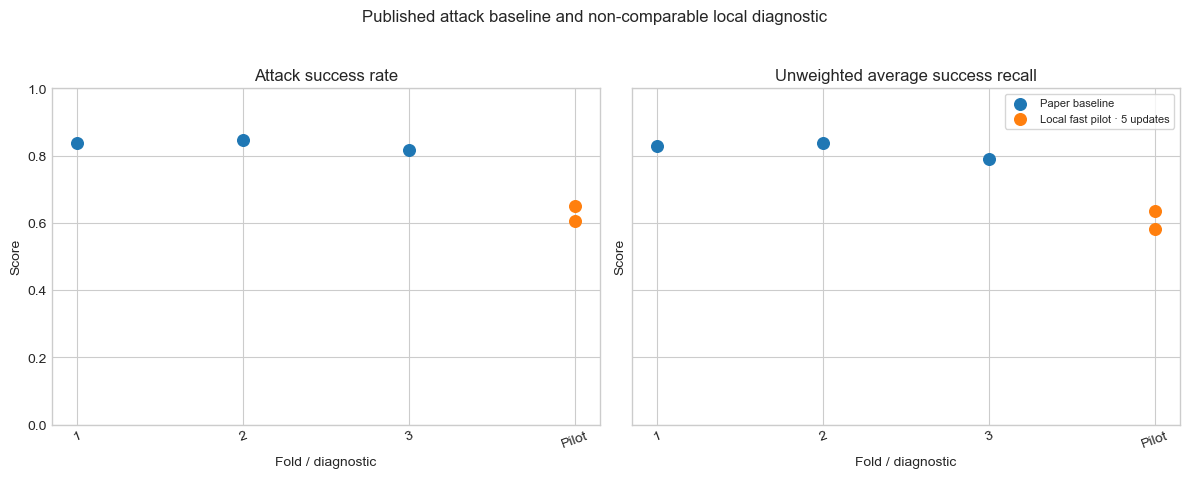

In [5]:
paper_attack = PAPER_BASELINE[["fold", "attack_sr", "attack_uasr"]].copy()
paper_attack["source"] = "Paper baseline"
attack_comparison = paper_attack.melt(id_vars=["fold", "source"], value_vars=["attack_sr", "attack_uasr"], var_name="metric", value_name="score")

if not attack_df.empty:
    for _, row in attack_df.iterrows():
        attack_comparison = pd.concat([attack_comparison, pd.DataFrame([{
            "fold": "Pilot", "source": f"Local fast pilot · {row['updates per client']} updates",
            "metric": "attack_sr", "score": row["attack SR"]
        }, {
            "fold": "Pilot", "source": f"Local fast pilot · {row['updates per client']} updates",
            "metric": "attack_uasr", "score": row["attack UASR"]
        }])], ignore_index=True)

display(attack_comparison.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, metric, title in zip(axes, ["attack_sr", "attack_uasr"], ["Attack success rate", "Unweighted average success recall"]):
    frame = attack_comparison[attack_comparison["metric"] == metric]
    for source, group in frame.groupby("source", sort=False):
        ax.scatter(group["fold"].astype(str), group["score"], s=70, label=source)
    ax.set(title=title, xlabel="Fold / diagnostic", ylabel="Score", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=20)
axes[1].legend(frameon=True, fontsize=8)
fig.suptitle("Published attack baseline and non-comparable local diagnostic", y=1.03)
fig.tight_layout()
plt.show()

## 5. Results interpretation and next steps

The current SER pilot shows higher validation scores than the paper's fold-1 baseline without protection, while UDP at epsilon 10 is slightly lower than this local baseline. Those differences cannot be attributed to the defence alone because feature extraction/normalization and actor fold assignments are not identical to a fully specified paper protocol.

The current fast attack diagnostic is lower than the published baseline, but it uses a downsampled network and is explicitly marked as a runtime deviation. It cannot establish that the attack has been mitigated. Voice-Ind and Gender-Ind have no downstream audio/SER/attack results in the available outputs, so no privacy-utility comparison across all three defences is available yet.

### Reproduction checklist

- [ ] Validate the exact emotion-label mapping and align preprocessing/features with author materials where possible.
- [ ] Run the full attack architecture on all three folds for 5, 10, and 100 observed updates.
- [ ] Complete the UDP epsilon sweep and audit clipping, adjacency, sampling, composition, and delta assumptions.
- [ ] Validate ESPnet synthesis; complete transformed-audio feature extraction and Voice-Ind/Gender-Ind training.
- [ ] Report per-fold and multi-seed means with uncertainty, plus class-wise and subgroup metrics.

### Reading the paper-to-thesis analysis

See [`paper_analysis_for_phd.md`](../paper_analysis_for_phd.md) for the detailed methods, materials, system architecture, experimental design, findings, discussion, limitations, research gaps, and suggested PhD study plan. The current project status and implementation deviations are also recorded in [`results/pilot_summary.md`](../results/pilot_summary.md).
